# How large can noise look?

Independent stocks can have nonzero correlations in a small sample. Simulate independent windows and compare their largest eigenvalues with the theoretical upper edge.

This is a seeded teaching example. Dates are illustrative.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from panic_detector.features.returns import daily_log_returns

rng = np.random.default_rng(2020)
dates = pd.bdate_range("2019-01-02", periods=320)
common = rng.normal(size=(320, 1))
strength = np.where(np.arange(320)[:, None] < 200, 0.18, 1.6)
moves = 0.009 * (rng.normal(size=(320, 8)) + strength * common)
prices = pd.DataFrame(100 * np.exp(moves.cumsum(axis=0)), index=dates, columns=list("ABCDEFGH"))
returns = daily_log_returns(prices)

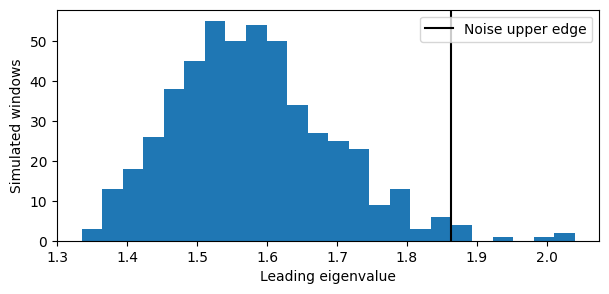

In [2]:
from panic_detector.models.random_matrix import marchenko_pastur_upper_bound
from panic_detector.models.eigen import top_eigenvalue
samples = [top_eigenvalue(np.corrcoef(rng.normal(size=(8, 60)))) for _ in range(500)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(samples, bins=24)
ax.axvline(marchenko_pastur_upper_bound(8, 60), color="black", label="Noise upper edge")
ax.set(xlabel="Leading eigenvalue", ylabel="Simulated windows")
ax.legend()
display(fig); plt.close(fig)